# Módulo 2 — Compresión y descompresión

| | |
|---|---|
| **Responde** | Pre-procesamiento (compresión) · hipótesis 3 como objetivo de máxima |
| **Código** | `compresion.py` (en esta misma carpeta) |
| **Recibe** | una imagen RGB float [0, 1] |
| **Devuelve** | `(img_descomprimida, cantidad_de_bytes)`, PSNR, SSIM, tasa de compresión |
| **Responsable** | _completar_ |

> Las funciones se programan en `compresion.py`. Este cuaderno sólo las llama, grafica y discute.
> Para guardar una figura para el informe: `graficos.guardar_figura(fig, "nombre")`.
> Para comprobar el módulo: `python main.py --revisar` desde la carpeta del repo.

In [1]:
# Permite usar el código de las otras carpetas del repo
import sys
sys.path.insert(0, "../..")

# Recarga los cambios que hagas en los archivos .py sin reiniciar el cuaderno
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

import pandas as pd
from skimage import color
from modulos.m0_carga_de_datos import carga_de_datos
from modulos.m2_compresion import compresion
from modulos.herramientas import graficos, lesion_de_prueba
from modulos.herramientas.procesamiento_completo import procesar, procesar_todos

graficos.aplicar_estilo()

tabla = carga_de_datos.leer_tabla_ph2()
entrenamiento = [carga_de_datos.cargar_caso(n, tabla) for n in carga_de_datos.nombres("entrenamiento")]
print(f"{len(entrenamiento)} imágenes de entrenamiento")

140 imágenes de entrenamiento


## Para qué está este módulo

La consigna pide que el trabajo incluya **compresión y descompresión** como paso de pre-procesamiento. En la práctica clínica, las imágenes dermatoscópicas muchas veces se guardan o se envían como JPEG (por ejemplo, en teledermatología), y JPEG **pierde información** para que el archivo ocupe menos.

La pregunta de fondo es: **si las imágenes llegan comprimidas, ¿cuánto se degradan, y qué partes de la imagen son las que más sufren?**

La devolución del anteproyecto pidió no hacer de esto el centro del trabajo. Por eso el módulo tiene dos niveles:

- **Núcleo (sección 1, hecho):** medir cuánto se comprime y cuánto se pierde.
- **Objetivo de máxima (sección 2, si sobra tiempo):** correr todo el algoritmo sobre imágenes comprimidas y ver si cambia el diagnóstico.

### Qué se hace, paso a paso

Para **cada una de las 140 imágenes de entrenamiento** y **cada una de las 5 calidades** de JPEG (95, 75, 50, 25 y 10):

1. **Se comprime** la imagen con JPEG a esa calidad, en memoria, sin guardar ningún archivo.
2. **Se cuenta cuántos bytes ocupa** el JPEG.
3. **Se descomprime**, y se obtiene una imagen del mismo tamaño que la original, pero un poco distinta.
4. **Se compara** la descomprimida con la original usando varias métricas.

Al final se resume cada calidad con la **mediana** de las 140 imágenes.

La **calidad** es un número de 1 a 100 que controla cuánto descarta JPEG. **No es un porcentaje del tamaño**: calidad 50 no significa "la mitad del archivo". Calidad alta = poca pérdida y archivo más grande; calidad baja = mucha pérdida y archivo chico.

## Qué es JPEG y por qué importa en este trabajo

La consigna pide incluir **compresión y descompresión** como paso de pre-procesamiento. Se usa **JPEG**, el formato con el que se guardan y se envían la mayoría de las fotos (incluidas muchas imágenes dermatoscópicas en teledermatología). Es una compresión **con pérdida**: la imagen descomprimida no es idéntica a la original, a cambio de ocupar mucho menos.

**Cómo comprime JPEG, en cuatro pasos:**

1. **Separa brillo y color.** Pasa de RGB a YCbCr: Y es el brillo y Cb, Cr son el color. El ojo es mucho más sensible al brillo que al color, así que el color se guarda a **la mitad de resolución en cada eje** (submuestreo de croma 4:2:0): un valor de color cada 2 × 2 píxeles.
2. **Divide en bloques de 8 × 8** y aplica a cada uno la **transformada discreta del coseno (DCT)**. La DCT reescribe el bloque como suma de patrones de distinta frecuencia: el primer coeficiente es el promedio del bloque y los siguientes son variaciones cada vez más finas.
3. **Cuantiza:** divide cada coeficiente por un número y redondea. Las frecuencias altas (detalle fino) se dividen por números grandes y muchas quedan en cero. **Este es el único paso donde se pierde información**, y el parámetro **calidad** (de 1 a 100) controla cuán grandes son esos divisores: calidad baja = más ceros = archivo más chico y más pérdida.
4. **Codifica sin pérdida** los coeficientes (muchos ceros seguidos ocupan muy poco).

**Qué se pierde, y por qué nos importa:**

- **Detalle fino** (frecuencias altas): justamente la **red de pigmento**, los puntos y el **borde** de la lesión, que usan M4 (criterio B) y M5 (textura).
- **Color**, por el submuestreo de croma: afecta al criterio C (M4).
- A calidades bajas aparecen **bloques de 8 × 8** visibles y halos en los bordes.

**Alcance (devolución del anteproyecto):** acá se hace el **núcleo** —comprimir, descomprimir y medir cuánto se comprime y cuánto se pierde—. Correr todo el algoritmo sobre imágenes comprimidas (hipótesis 3) queda como **objetivo de máxima** (sección 2).

## Prueba con una lesión inventada

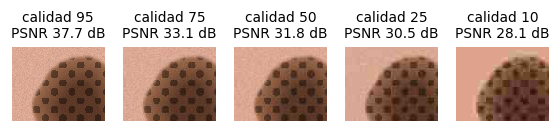

In [2]:
img, info = lesion_de_prueba.generar_lesion(semilla=2, textura=0.4)
fig, ax = plt.subplots(1, len(compresion.CALIDADES))
for a, q in zip(ax, compresion.CALIDADES):
    rec, n = compresion.comprimir_jpeg(img, q)
    graficos.mostrar(a, rec[60:140, 120:220], f"calidad {q}\nPSNR {compresion.psnr(img, rec):.1f} dB")

## 1. Núcleo: cuánto se comprime y cuánto se pierde

- [x] Tabla: calidad → tasa de compresión, PSNR (imagen completa y dentro de la lesión), SSIM, sobre las imágenes de entrenamiento.
- [x] Figura: detalle de la red de pigmento a varias calidades (¿aparecen bloques de 8×8? ¿se pierden colores?).
- [x] Explicar brevemente por qué JPEG pierde lo que pierde (DCT + cuantización + submuestreo de croma).

### Las métricas, explicadas

**Tasa de compresión: cuánto se achica.** La imagen sin comprimir ocupa alto × ancho × 3 bytes (un byte por canal R, G y B). Para una de 767 × 576 son unos 1,3 MB. Si el JPEG ocupa 55 kB, la tasa es 1,3 MB / 55 kB ≈ **24**: el archivo es 24 veces más chico.

**PSNR: cuánto cambian los píxeles, en promedio.** Se resta la imagen original menos la descomprimida píxel por píxel, se eleva al cuadrado y se promedia (es el error cuadrático medio, MSE). El PSNR lo pasa a una escala logarítmica en decibeles, PSNR = 10·log₁₀(1/MSE): **más alto = más parecidas**. Como referencia:

- más de 40 dB: la diferencia casi no se ve;
- entre 30 y 40 dB: se nota si uno mira con atención;
- menos de 30 dB: se nota claramente.

Se calcula dos veces: en toda la imagen y **sólo dentro de la lesión** (máscara de PH2), que es la zona que importa para el diagnóstico.

**SSIM: cuánto cambia la estructura.** El PSNR trata a todos los píxeles por separado. El SSIM, en cambio, compara **ventanitas** de la imagen: si tienen el mismo brillo medio, el mismo contraste y el mismo **patrón** [Wang et al., 2004]. Se parece más a cómo percibe el ojo. Vale 1 si son idénticas y baja a medida que se pierde estructura. Nos interesa especialmente porque la "estructura local" es justamente la **textura** (la red de pigmento) que mide M5.

**ΔE: cuánto cambia el color.** Se pasa la imagen al espacio Lab, donde la distancia entre dos colores se parece a qué tan distintos los ve una persona, y se mide la distancia media entre el color original y el comprimido dentro de la lesión (fórmula CIE76). Un ΔE de **2,3** es el cambio apenas perceptible. Esto importa para el **criterio C**, que cuenta colores.

| Métrica | Qué mide | Cómo se lee |
|---|---|---|
| Tasa de compresión | Bytes sin comprimir / bytes del JPEG | 20 = ocupa 20 veces menos |
| PSNR (dB) | Error medio píxel a píxel | > 40 casi invisible; < 30 se nota |
| PSNR en la lesión | Lo mismo, sólo en la lesión | La zona del diagnóstico |
| SSIM | Similitud de estructura local | 1 = idénticas |
| ΔE en la lesión | Cambio de color medio | > 2,3 perceptible |

El cálculo tarda alrededor de un minuto y medio, sobre todo por el SSIM.

In [3]:
filas = []
for caso in entrenamiento:
    lab = color.rgb2lab(caso.imagen)
    for q in compresion.CALIDADES:
        rec, n = compresion.comprimir_jpeg(caso.imagen, q)
        delta_e = np.linalg.norm(lab - color.rgb2lab(rec), axis=-1)[caso.mascara_ref].mean()
        filas.append({
            "nombre": caso.nombre, "calidad": q,
            "tasa": compresion.tasa_de_compresion(caso.imagen, n),
            "PSNR": compresion.psnr(caso.imagen, rec),
            "PSNR lesión": compresion.psnr(caso.imagen, rec, caso.mascara_ref),
            "SSIM": compresion.ssim(caso.imagen, rec),
            "ΔE lesión": delta_e,
        })
metricas = pd.DataFrame(filas)
resumen = metricas.drop(columns="nombre").groupby("calidad").median().sort_index(ascending=False)
graficos.guardar_tabla(resumen.reset_index(), "m2_compresion")
resumen.round(2)

,tasa,PSNR,PSNR lesión,SSIM,ΔE lesión
calidad,,,,,
95,8.22,41.13,40.65,0.97,1.95
75,23.66,35.91,34.87,0.89,2.74
50,39.73,34.47,33.42,0.85,3.15
25,67.66,32.78,31.65,0.80,3.85
10,121.80,29.60,28.67,0.70,5.77


WindowsPath('C:/Users/Facu/Desktop/1er Cuatri 4to (Bioingenieria)/Procesamiento de Señales e Imagenes Biomedicas/TP Imagenes - Final/PSIB2026Q2-TPI-Grupo02-CassanoNieto-DElia-Ortega/informe/figuras/m2_compromiso.pdf')

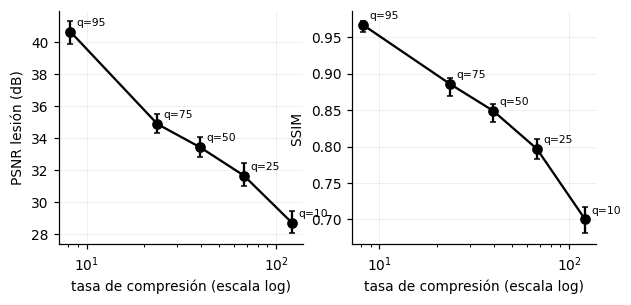

In [4]:
# Compromiso entre compresión y calidad: cada punto es una calidad de JPEG (mediana sobre entrenamiento)
fig, ax = plt.subplots(1, 2)
for a, metrica, unidad in [(ax[0], "PSNR lesión", "dB"), (ax[1], "SSIM", "")]:
    g = metricas.groupby("calidad")
    x, y = g["tasa"].median(), g[metrica].median()
    a.errorbar(x, y, yerr=[y - g[metrica].quantile(0.25), g[metrica].quantile(0.75) - y], fmt="o-", color="k", capsize=2)
    for q in compresion.CALIDADES:
        a.annotate(f"q={q}", (x[q], y[q]), textcoords="offset points", xytext=(4, 4), fontsize=7)
    a.set_xscale("log")
    a.set_xlabel("tasa de compresión (escala log)")
    a.set_ylabel(f"{metrica} {f'({unidad})' if unidad else ''}")
graficos.guardar_figura(fig, "m2_compromiso")

WindowsPath('C:/Users/Facu/Desktop/1er Cuatri 4to (Bioingenieria)/Procesamiento de Señales e Imagenes Biomedicas/TP Imagenes - Final/PSIB2026Q2-TPI-Grupo02-CassanoNieto-DElia-Ortega/informe/figuras/m2_detalle.pdf')

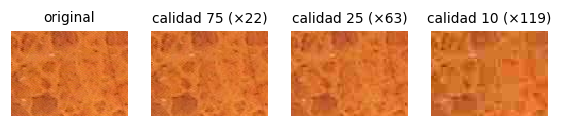

In [5]:
# Detalle de la red de pigmento (dentro de la lesión) a varias calidades
caso = carga_de_datos.cargar_caso("IMD200", tabla)
f, c = np.argwhere(caso.mascara_ref).mean(axis=0).astype(int)
recorte = (slice(f - 40, f + 40), slice(c - 120, c - 10))      # zona con red de pigmento
fig, ax = plt.subplots(1, 4)
graficos.mostrar(ax[0], caso.imagen[recorte], "original")
for a, q in zip(ax[1:], (75, 25, 10)):
    rec, n = compresion.comprimir_jpeg(caso.imagen, q)
    graficos.mostrar(a, rec[recorte], f"calidad {q} (×{compresion.tasa_de_compresion(caso.imagen, n):.0f})")
graficos.guardar_figura(fig, "m2_detalle")

### Conclusiones del núcleo

**Cómo leer la tabla:**

1. **JPEG es muy eficiente.** A calidad 95 la imagen ocupa unas 8 veces menos y la pérdida es invisible (PSNR > 40 dB, SSIM ≈ 0,97, color sin cambio perceptible). A calidad 75, la más habitual por defecto, ocupa unas 24 veces menos.
2. **La lesión sufre más que la piel.** El PSNR dentro de la lesión es siempre ≈ 1 dB menor que el de la imagen completa. JPEG descarta primero el **detalle fino**, y la lesión tiene mucho más (red, puntos, borde) que la piel lisa.
3. **El SSIM cae más rápido que el PSNR.** Entre calidad 95 y 10 el SSIM pasa de ≈ 0,97 a ≈ 0,70: lo que más se pierde es la **estructura**, es decir, la textura.
4. **El color se empieza a notar a partir de calidad 75.** La diferencia de color media en la lesión (ΔE) es ≈ 2 a calidad 95, por debajo de lo perceptible (≈ 2,3); ≈ 2,7 a calidad 75, apenas perceptible, y ≈ 5,8 a calidad 10, claramente visible.

**La figura del detalle** lo muestra a ojo: a calidad 25 la red de pigmento se suaviza, y a calidad 10 se reemplaza por **bloques cuadrados de 8 × 8**, la "huella" típica de JPEG.

### Qué significa para el resto del trabajo

Se puede anticipar qué partes del algoritmo serían más frágiles ante la compresión:

- **Segmentación (M3):** trabaja con formas grandes, así que debería resistir bien.
- **Textura (M5) y borde (criterio B):** dependen del detalle fino, así que son lo más sensible.
- **Color (criterio C):** afectado a calidades bajas.

Es una **predicción**, no un resultado: comprobarla es el objetivo de máxima (sección 2).

## 2. Objetivo de máxima (sólo si sobra tiempo)

- [ ] `procesar(caso, calidad_jpeg=q)` para cada calidad: Dice, sensibilidad y especificidad vs. calidad.

Cuando estén M3 a M7, la celda de abajo (ahora comentada) corre todo el algoritmo con `procesar(caso, calidad_jpeg=q)` y mide cuánto cambian el Dice, la sensibilidad y la especificidad a cada calidad. Así se comprueba la predicción de la sección anterior.

No hay que programar nada nuevo en M2: `procesar(caso, calidad_jpeg=q)` ya comprime y descomprime la imagen antes de todo el resto del algoritmo.

In [6]:
# OBJETIVO DE MÁXIMA (cuando M3 esté listo; para sensibilidad y especificidad hace falta M7)
# filas = []
# for caso in entrenamiento:
#     for q in (None, *compresion.CALIDADES):
#         res = procesar(caso, hasta="segmentacion", calidad_jpeg=q)
#         filas.append({"nombre": caso.nombre, "calidad": q or 100, "dice": res.dice})
# pd.DataFrame(filas).groupby("calidad")["dice"].describe()